Dataset Path: /kaggle/input/datasets/ahemateja19bec1025/traffic-sign-dataset-classification/traffic_Data
Path Exists: True

========== DATASET CONTENT ==========
📁 Folder: DATA
📁 Folder: TEST

========== IMAGE INFORMATION ==========
Total Images: 6164
Total Classes/Folders: 2

Classes:
['DATA', 'TEST']

========== CLASS DISTRIBUTION ==========
Class  Image_Count
 DATA            0
 TEST         1994

========== BASIC STATISTICS ==========
Total Images: 1994
Number of Classes: 2
Maximum Images in a Class: 1994
Minimum Images in a Class: 0


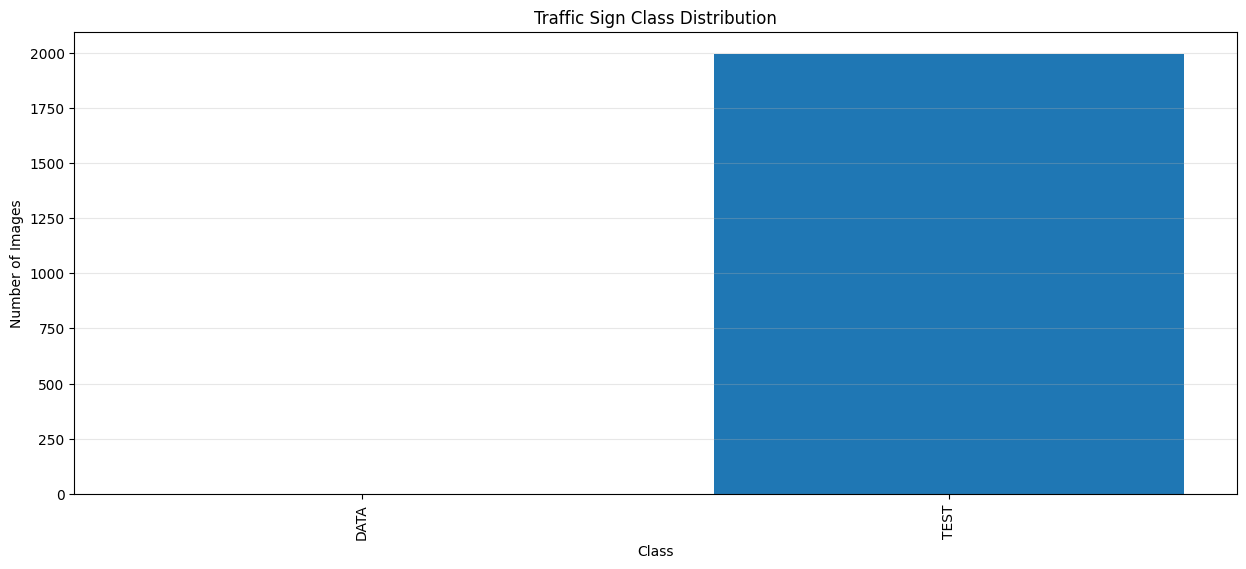


========== SAMPLE IMAGES ==========


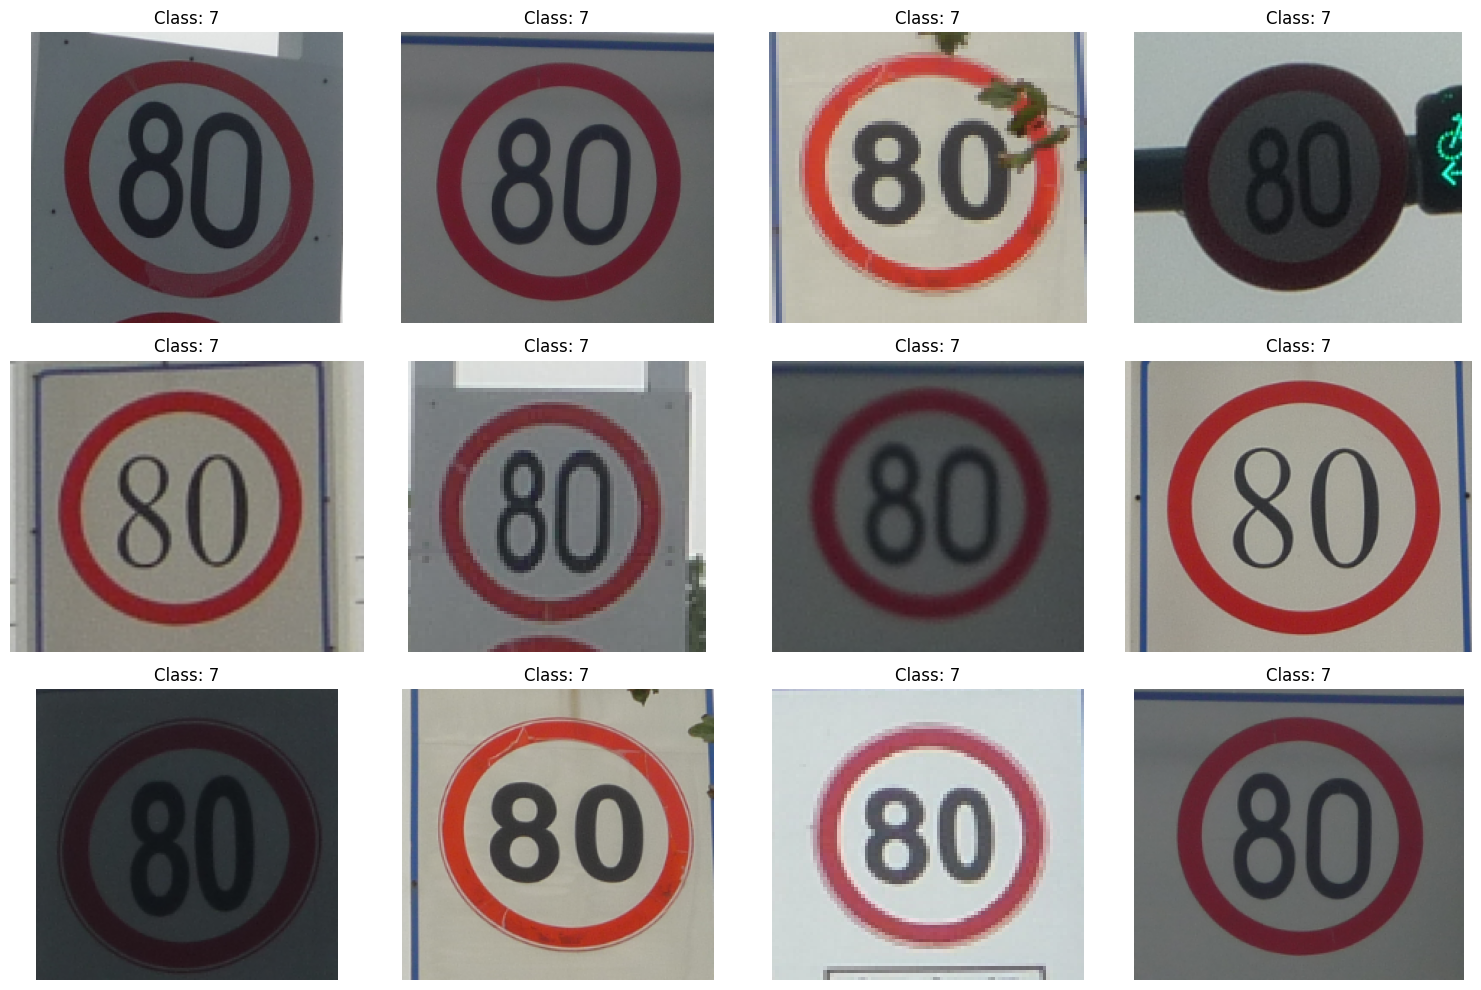


========== IMAGE SIZE CHECK ==========
            Width      Height
count  500.000000  500.000000
mean   156.428000  142.990000
std     57.674514   50.998427
min     64.000000   63.000000
25%    114.000000  103.000000
50%    146.000000  135.000000
75%    189.250000  175.500000
max    491.000000  402.000000

Most common image sizes:
Width  Height
120    102       8
93     88        4
111    102       4
120    109       4
113    108       4
209    195       4
170    161       4
162    150       4
248    231       2
246    230       2
Name: count, dtype: int64

========== CSV FILES ==========
No CSV file found.

========== EDA COMPLETED ==========


In [1]:
# ============================================================
# TRAFFIC SIGN DATASET - LOAD + EDA
# ============================================================

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ------------------------------------------------------------
# 1. Dataset Path
# ------------------------------------------------------------
DATASET_PATH = "/kaggle/input/datasets/ahemateja19bec1025/traffic-sign-dataset-classification/traffic_Data"

print("Dataset Path:", DATASET_PATH)
print("Path Exists:", os.path.exists(DATASET_PATH))

# ------------------------------------------------------------
# 2. Show files and folders
# ------------------------------------------------------------
print("\n========== DATASET CONTENT ==========")

for item in os.listdir(DATASET_PATH):
    full_path = os.path.join(DATASET_PATH, item)
    if os.path.isdir(full_path):
        print("📁 Folder:", item)
    else:
        print("📄 File:", item)

# ------------------------------------------------------------
# 3. Find image files
# ------------------------------------------------------------
image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]

image_files = []

for ext in image_extensions:
    image_files.extend(
        glob.glob(os.path.join(DATASET_PATH, "**", ext), recursive=True)
    )

print("\n========== IMAGE INFORMATION ==========")
print("Total Images:", len(image_files))

# ------------------------------------------------------------
# 4. Find class folders
# ------------------------------------------------------------
class_folders = []

for item in os.listdir(DATASET_PATH):
    full_path = os.path.join(DATASET_PATH, item)

    if os.path.isdir(full_path):
        class_folders.append(item)

class_folders = sorted(class_folders)

print("Total Classes/Folders:", len(class_folders))

print("\nClasses:")
print(class_folders)

# ------------------------------------------------------------
# 5. Count images in each class
# ------------------------------------------------------------
class_counts = {}

for class_name in class_folders:
    
    class_path = os.path.join(DATASET_PATH, class_name)
    
    count = 0
    
    for ext in image_extensions:
        count += len(glob.glob(os.path.join(class_path, ext)))
    
    class_counts[class_name] = count

class_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image_Count"]
)

print("\n========== CLASS DISTRIBUTION ==========")
print(class_df.to_string(index=False))

# ------------------------------------------------------------
# 6. Basic statistics
# ------------------------------------------------------------
print("\n========== BASIC STATISTICS ==========")

print("Total Images:", class_df["Image_Count"].sum())
print("Number of Classes:", len(class_df))
print("Maximum Images in a Class:", class_df["Image_Count"].max())
print("Minimum Images in a Class:", class_df["Image_Count"].min())

# ------------------------------------------------------------
# 7. Class Distribution Plot
# ------------------------------------------------------------
plt.figure(figsize=(15, 6))

plt.bar(
    class_df["Class"].astype(str),
    class_df["Image_Count"]
)

plt.title("Traffic Sign Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)

plt.show()

# ------------------------------------------------------------
# 8. Display Sample Images
# ------------------------------------------------------------
print("\n========== SAMPLE IMAGES ==========")

sample_images = image_files[:12]

plt.figure(figsize=(15, 10))

for i, img_path in enumerate(sample_images):

    try:
        img = Image.open(img_path)

        plt.subplot(3, 4, i + 1)
        plt.imshow(img)
        plt.axis("off")

        # Get class from parent folder
        class_name = os.path.basename(os.path.dirname(img_path))
        plt.title(f"Class: {class_name}")

    except Exception as e:
        print("Error:", img_path, e)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Check Image Sizes
# ------------------------------------------------------------
print("\n========== IMAGE SIZE CHECK ==========")

sizes = []

for img_path in image_files[:500]:  # first 500 images
    try:
        img = Image.open(img_path)
        sizes.append(img.size)
    except:
        pass

if sizes:

    size_df = pd.DataFrame(
        sizes,
        columns=["Width", "Height"]
    )

    print(size_df.describe())

    print("\nMost common image sizes:")
    print(size_df.value_counts().head(10))

# ------------------------------------------------------------
# 10. Check labels.csv if available
# ------------------------------------------------------------
labels_files = glob.glob(
    os.path.join(DATASET_PATH, "**", "*.csv"),
    recursive=True
)

print("\n========== CSV FILES ==========")

if labels_files:

    for csv_file in labels_files:
        print("CSV:", csv_file)

        try:
            df = pd.read_csv(csv_file)

            print("\nShape:", df.shape)
            print("\nColumns:")
            print(df.columns.tolist())

            print("\nFirst 5 rows:")
            display(df.head())

        except Exception as e:
            print("Could not read:", e)

else:
    print("No CSV file found.")

print("\n========== EDA COMPLETED ==========")

In [2]:
# ============================================================
# TRAFFIC SIGN DATASET - PREPROCESSING FOR CNN
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

# ------------------------------------------------------------
# 1. Dataset Path
# ------------------------------------------------------------
DATASET_PATH = "/kaggle/input/datasets/ahemateja19bec1025/traffic-sign-dataset-classification/traffic_Data"

# ------------------------------------------------------------
# 2. Image Settings
# ------------------------------------------------------------
IMG_SIZE = 64
CHANNELS = 3

X = []
y = []

# ------------------------------------------------------------
# 3. Get Class Folders
# ------------------------------------------------------------
class_folders = sorted([
    folder for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
])

print("Classes:", class_folders)
print("Number of Classes:", len(class_folders))

# Create class -> integer mapping
class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_folders)
}

print("\nClass Mapping:")
print(class_to_index)

# ------------------------------------------------------------
# 4. Load and Preprocess Images
# ------------------------------------------------------------
image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]

for class_name in class_folders:

    class_path = os.path.join(DATASET_PATH, class_name)

    image_files = []

    for ext in image_extensions:
        image_files.extend(
            glob.glob(os.path.join(class_path, ext))
        )

    label = class_to_index[class_name]

    for img_path in image_files:

        try:
            # Open image
            img = Image.open(img_path)

            # Convert to RGB
            img = img.convert("RGB")

            # Resize image
            img = img.resize((IMG_SIZE, IMG_SIZE))

            # Convert image to NumPy array
            img = np.array(img)

            X.append(img)
            y.append(label)

        except Exception as e:
            print("Error:", img_path, e)

# ------------------------------------------------------------
# 5. Convert to NumPy Arrays
# ------------------------------------------------------------
X = np.array(X, dtype=np.float32)
y = np.array(y)

print("\n========== BEFORE NORMALIZATION ==========")
print("X Shape:", X.shape)
print("y Shape:", y.shape)
print("Pixel Minimum:", X.min())
print("Pixel Maximum:", X.max())

# ------------------------------------------------------------
# 6. Normalize Pixel Values
# ------------------------------------------------------------
# Convert 0-255 pixels into 0-1
X = X / 255.0

print("\n========== AFTER NORMALIZATION ==========")
print("Pixel Minimum:", X.min())
print("Pixel Maximum:", X.max())

# ------------------------------------------------------------
# 7. Train / Validation / Test Split
# ------------------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\n========== DATA SPLIT ==========")
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

# ------------------------------------------------------------
# 8. One-Hot Encoding Labels
# ------------------------------------------------------------
NUM_CLASSES = len(class_folders)

y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_val_cat = to_categorical(y_val, NUM_CLASSES)
y_test_cat = to_categorical(y_test, NUM_CLASSES)

print("\n========== LABEL ENCODING ==========")
print("Original label:", y_train[0])
print("One-hot label:", y_train_cat[0])

# ------------------------------------------------------------
# 9. Final Summary
# ------------------------------------------------------------
print("\n========== PREPROCESSING COMPLETED ==========")

print("Image Size:", IMG_SIZE, "x", IMG_SIZE)
print("Channels:", CHANNELS)
print("Number of Classes:", NUM_CLASSES)

print("\nFinal Shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train_cat.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val_cat.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test_cat.shape)

Classes: ['DATA', 'TEST']
Number of Classes: 2

Class Mapping:
{'DATA': 0, 'TEST': 1}

========== BEFORE NORMALIZATION ==========
X Shape: (1994, 64, 64, 3)
y Shape: (1994,)
Pixel Minimum: 0.0
Pixel Maximum: 255.0

========== AFTER NORMALIZATION ==========
Pixel Minimum: 0.0
Pixel Maximum: 1.0

========== DATA SPLIT ==========
Training: (1395, 64, 64, 3) (1395,)
Validation: (299, 64, 64, 3) (299,)
Testing: (300, 64, 64, 3) (300,)

========== LABEL ENCODING ==========
Original label: 1
One-hot label: [0. 1.]

========== PREPROCESSING COMPLETED ==========
Image Size: 64 x 64
Channels: 3
Number of Classes: 2

Final Shapes:
X_train: (1395, 64, 64, 3)
y_train: (1395, 2)
X_val: (299, 64, 64, 3)
y_val: (299, 2)
X_test: (300, 64, 64, 3)
y_test: (300, 2)


In [3]:
# ============================================================
# TRAFFIC SIGN CLASSIFICATION - CNN MODEL TRAINING
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# ------------------------------------------------------------
# 1. CNN Model
# ------------------------------------------------------------

model = Sequential([

    # First Convolution Block
    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(64, 64, 3)
    ),
    MaxPooling2D((2, 2)),

    # Second Convolution Block
    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    MaxPooling2D((2, 2)),

    # Third Convolution Block
    Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),
    MaxPooling2D((2, 2)),

    # Convert feature maps into vector
    Flatten(),

    # Fully Connected Layer
    Dense(128, activation="relu"),

    # Dropout to reduce overfitting
    Dropout(0.5),

    # Output Layer
    Dense(NUM_CLASSES, activation="softmax")
])

# ------------------------------------------------------------
# 2. Model Summary
# ------------------------------------------------------------

model.summary()

# ------------------------------------------------------------
# 3. Compile Model
# ------------------------------------------------------------

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# 4. Train Model
# ------------------------------------------------------------

EPOCHS = 20
BATCH_SIZE = 32

history = model.fit(
    X_train,
    y_train_cat,

    validation_data=(
        X_val,
        y_val_cat
    ),

    epochs=EPOCHS,
    batch_size=BATCH_SIZE,

    verbose=1
)

# ------------------------------------------------------------
# 5. Final Test Evaluation
# ------------------------------------------------------------

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_cat,
    verbose=1
)

print("\n======================================")
print("CNN MODEL TRAINING COMPLETED")
print("======================================")

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-09-21 12:41:35.498133: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,458 (2.61 MB)

 Trainable params: 683,458 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - accuracy: 0.9864 - loss: 0.0196 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step 

Number of classes: 2
Actual classes   : [1]
Predicted classes: [1]
All classes      : [0 1]

CNN EVALUATION
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1 Score  : 1.0000

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        DATA       0.00      0.00      0.00         0
        TEST       1.00      1.00      1.00       300

    accuracy                           1.00       300
   macro avg       0.50      0.50      0.50       300
weighted avg       1.00      1.00      1.00       300



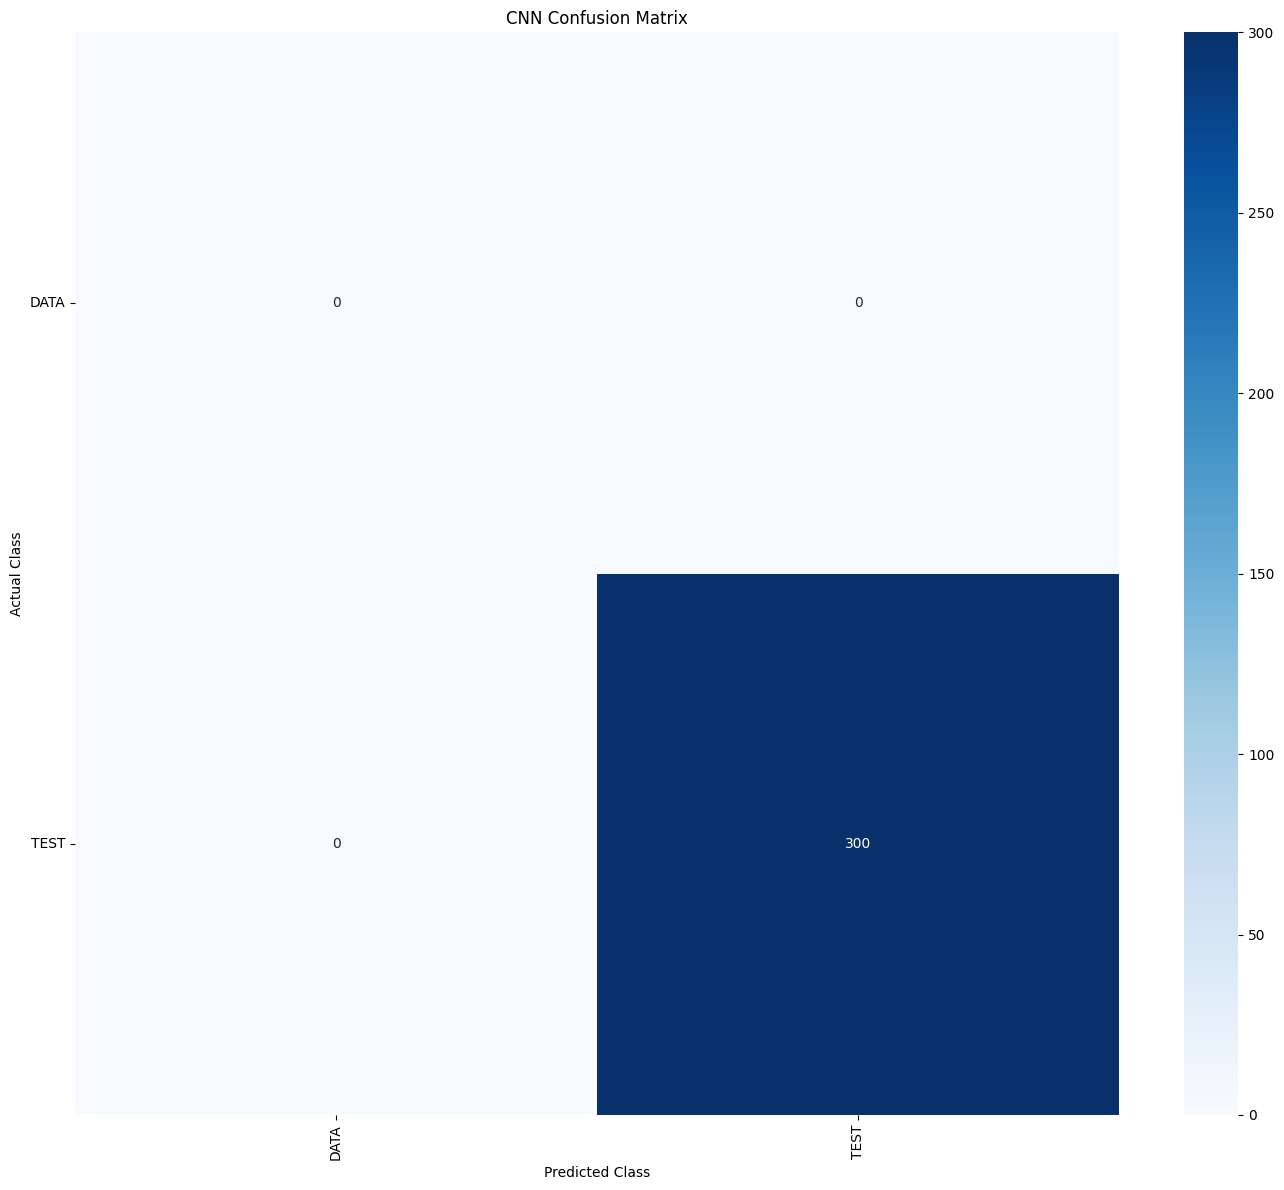


FINAL TEST RESULT
Test Loss     : 0.0000
Test Accuracy : 1.0000

PREDICTION SUMMARY
Total Images : 300
Correct      : 300
Wrong        : 0


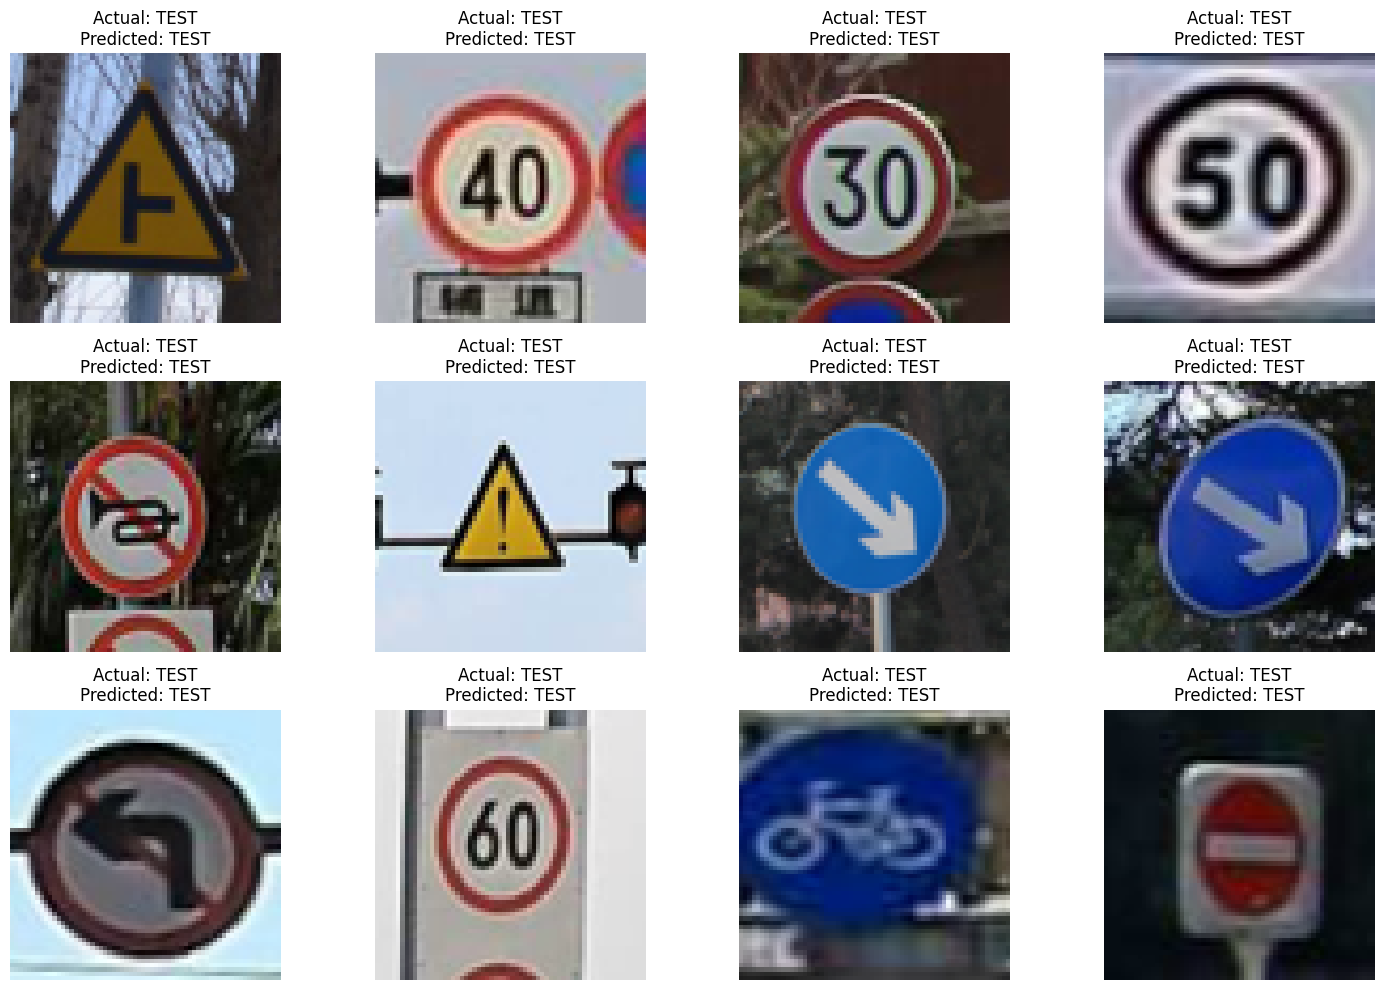


========== COMPLETED ==========


In [6]:
# ============================================================
# CNN EVALUATION + CONFUSION MATRIX - ONE CELL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. PREDICTION
# ------------------------------------------------------------

y_pred_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.asarray(y_test).astype(int)

# ------------------------------------------------------------
# 2. ALL KNOWN LABELS
# ------------------------------------------------------------

# Model ke saare possible classes
all_labels = np.arange(NUM_CLASSES)

print("Number of classes:", NUM_CLASSES)
print("Actual classes   :", np.unique(y_true))
print("Predicted classes:", np.unique(y_pred))
print("All classes      :", all_labels)

# ------------------------------------------------------------
# 3. CLASS NAMES
# ------------------------------------------------------------

if len(class_folders) == NUM_CLASSES:
    class_names = class_folders
else:
    class_names = [f"Class {i}" for i in all_labels]

# ------------------------------------------------------------
# 4. EVALUATION METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    labels=all_labels,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    labels=all_labels,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    labels=all_labels,
    average="weighted",
    zero_division=0
)

print("\n================================")
print("CNN EVALUATION")
print("================================")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

# ------------------------------------------------------------
# 5. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n================================")
print("CLASSIFICATION REPORT")
print("================================")

print(
    classification_report(
        y_true,
        y_pred,
        labels=all_labels,
        target_names=class_names,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=all_labels
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. TEST LOSS + ACCURACY
# ------------------------------------------------------------

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_cat,
    verbose=0
)

print("\n================================")
print("FINAL TEST RESULT")
print("================================")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")

# ------------------------------------------------------------
# 8. PREDICTION SUMMARY
# ------------------------------------------------------------

correct = np.sum(y_true == y_pred)
wrong = np.sum(y_true != y_pred)

print("\n================================")
print("PREDICTION SUMMARY")
print("================================")
print("Total Images :", len(y_true))
print("Correct      :", correct)
print("Wrong        :", wrong)

# ------------------------------------------------------------
# 9. SAMPLE PREDICTIONS
# ------------------------------------------------------------

plt.figure(figsize=(15, 10))

num_images = min(12, len(X_test))

for i in range(num_images):

    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i])

    actual = class_names[y_true[i]]
    predicted = class_names[y_pred[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

print("\n========== COMPLETED ==========")